In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap

**load data**

In [2]:
# # saving only the added delta values and biosample/DHS inds
# for i in range(1, 11):
#     print(i)
#     #load npz file
#     filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100unique_cycle'+str(i)+'_CT20220301.npz'
#     cycle_np_file = np.load(filename)
    
#     inds_to_1 = cycle_np_file['inds_to_1']
#     inds_to_0 = cycle_np_file['inds_to_0']
    
#     diff_flat_array = cycle_np_file['diff_flat_array']
    
#     #in order of first removed and first added to last removed and last added
#     sorted_inds_to_0 = inds_to_0[np.argsort(diff_flat_array[inds_to_0])]
#     sorted_inds_to_1 = inds_to_1[np.argsort(-diff_flat_array[inds_to_1])]
    
#     #corresponding delta vals
#     sorted_diff_removed = diff_flat_array[sorted_inds_to_0]
#     sorted_diff_added = diff_flat_array[sorted_inds_to_1]
    
#     #save
#     new_filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100unique_cycle'+str(i)+'_added_removed_CT20220302.npz'
#     np.savez(new_filename, added_delta=sorted_diff_added, removed_delta=sorted_diff_removed, added_flat_inds=sorted_inds_to_1, removed_flat_inds=sorted_inds_to_0)

1
2
3
4
5
6
7
8
9
10


In [2]:
#load npz file
added_delta_all_cycles = []
removed_delta_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 11):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100unique_cycle'+str(i)+'_added_removed_CT20220302.npz'
    cycle_np_file = np.load(filename)
    added_delta_all_cycles.append(cycle_np_file['added_delta'])
    removed_delta_all_cycles.append(cycle_np_file['removed_delta'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [39]:
#showing that by taking the top 100 unique delta values, the only change in added call order is in
#cycle 9 where the order of two calls are switched

#load npz file
delta_vals_all_cycles = []
DHS_inds_all_cycles = []
biosample_inds_all_cycles = []

for i in range(1, 11):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100_cycle'+str(i)+'_addedonly_CT20220224.npz'
    cycle_np_file = np.load(filename)
    delta_vals_all_cycles.append(cycle_np_file['delta_vals'])
    DHS_inds_all_cycles.append(cycle_np_file['DHS_inds'])
    biosample_inds_all_cycles.append(cycle_np_file['biosample_inds'])
    
delta_vals_all_cycles = np.array(delta_vals_all_cycles)
DHS_inds_all_cycles = np.array(DHS_inds_all_cycles)
biosample_inds_all_cycles = np.array(biosample_inds_all_cycles)

t0 = np.array(added_flat_inds_all_cycles)
t1 = (np.int64(biosample_inds_all_cycles) * n_DHSs) + np.int64(DHS_inds_all_cycles)
(t1-t0)[8]

array([         0,          0,          0,          0,          0,
                0,          0,          0,          0,          0,
                0,          0,          0,          0,          0,
                0,          0,          0,          0,          0,
                0,          0,          0,          0,          0,
                0,          0,          0,          0,          0,
                0,          0,          0,          0,          0,
                0,          0,          0,          0,          0,
                0,          0,          0,          0,          0,
                0,          0,          0,          0,          0,
                0,          0,          0,          0,          0,
                0,          0,          0,          0,          0,
                0,          0,          0,          0,          0,
                0,          0,          0, -134437334,  134437334,
                0,          0,          0,          0,        

In [4]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
dhs = pd.read_table('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38.txt.gz', header=None).T
print(dhs.shape)
dhs_array = dhs.to_numpy().astype(bool)
# np.save('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy', dhs_array)
del dhs

In [3]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/DHS_peak_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220215.npy'
DHS_peak_signal_array = np.load(file)

In [4]:
n_biosamples, n_DHSs = DHS_peak_signal_array.shape

In [20]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [18]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

**Removing 1 to 1 interactions**

In [8]:
filtered_added_delta_all_cycles = []
filtered_added_flat_inds_all_cycles = []

for i in range(10):
    print(i)
    #when i=0, that is referring to cycle 1 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (original) array value
    if i==0:
        #read in 733 sample x 3.5+ million DHS presence/absence matrix
        dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')
        
    #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (cycle 1) array value
    else:
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_booldhsarr_basis_mixture_fillsize100unique_cycle'+str(i)+'_CT20220301.npz'
        np_file = np.load(filename)
        dhs_arr = np_file['new_dhs_array']
    
    n_biosamples, n_DHSs = dhs_arr.shape
    
    added_flat_inds_single_cycle = []
    delta_vals_single_cycle = []
    
    #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (cycle 1) array value
    for flat_ind, delta in zip(added_flat_inds_all_cycles[i], added_delta_all_cycles[i]):
        biosample = flat_ind // n_DHSs
        dhs = flat_ind % n_DHSs
        if ~dhs_arr[biosample, dhs]:
            added_flat_inds_single_cycle.append(flat_ind)
            delta_vals_single_cycle.append(delta)
    
    del dhs_arr
    filtered_added_flat_inds_all_cycles.append(np.array(added_flat_inds_single_cycle))
    filtered_added_delta_all_cycles.append(np.array(delta_vals_single_cycle))

0
1
2
3
4
5
6
7
8
9


In [88]:
for i in range(len(filtered_added_flat_inds_all_cycles)):
    print('Percent of calls changed from 1 to 1 in cycle %s: %s' %(i+1, np.round((1-len(filtered_added_flat_inds_all_cycles[i])/100)*100)))

Percent of calls changed from 1 to 1 in cycle 1: 0.0
Percent of calls changed from 1 to 1 in cycle 2: 0.0
Percent of calls changed from 1 to 1 in cycle 3: 0.0
Percent of calls changed from 1 to 1 in cycle 4: 0.0
Percent of calls changed from 1 to 1 in cycle 5: 0.0
Percent of calls changed from 1 to 1 in cycle 6: 1.0
Percent of calls changed from 1 to 1 in cycle 7: 1.0
Percent of calls changed from 1 to 1 in cycle 8: 2.0
Percent of calls changed from 1 to 1 in cycle 9: 2.0
Percent of calls changed from 1 to 1 in cycle 10: 3.0


Text(0.5, 1.0, 'Delta Values for Removed Calls from Each Cycle\nDelta Flip, Flip Size=100 Unique Delta Values')

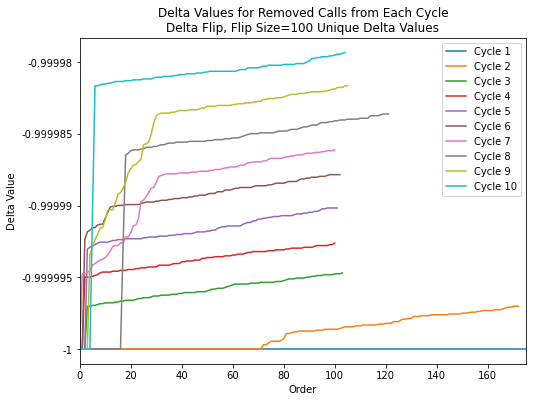

In [95]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(10):
    plt.plot(np.arange(len(removed_delta_all_cycles[i])), removed_delta_all_cycles[i])

plt.legend(['Cycle 1', 'Cycle 2', 'Cycle 3', 'Cycle 4', 'Cycle 5', 'Cycle 6', 'Cycle 7', 'Cycle 8', 'Cycle 9', 'Cycle 10'])
plt.yticks([-1, -0.999995, -0.99999, -0.999985, -0.99998], [-1, -0.999995, -0.99999, -0.999985, -0.99998])
# plt.yscale('symlog')
plt.xlim([0, 175])
# plt.xlim([22453, 22553])
plt.xlabel('Order')
plt.ylabel('Delta Value')
plt.title('Delta Values for Removed Calls from Each Cycle\nDelta Flip, Flip Size=100 Unique Delta Values')

Text(0.5, 1.0, 'Delta Values for Added (Previously 0) Calls from Each Cycle\nDelta Flip, Flip Size=100 Unique Delta Values')

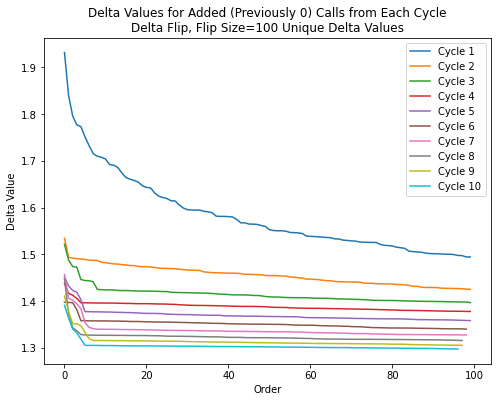

In [94]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(10):
    plt.plot(np.arange(len(filtered_added_delta_all_cycles[i])), filtered_added_delta_all_cycles[i])


plt.legend(['Cycle 1', 'Cycle 2', 'Cycle 3', 'Cycle 4', 'Cycle 5', 'Cycle 6', 'Cycle 7', 'Cycle 8', 'Cycle 9', 'Cycle 10'])

plt.xlabel('Order')
plt.ylabel('Delta Value')
plt.title('Delta Values for Added (Previously 0) Calls from Each Cycle\nDelta Flip, Flip Size=100 Unique Delta Values')

**Plotting delta vs peak signal and peak signal vs mean signal for added and removed calls**

In [5]:
#finding peak signal values of added calls
removed_peak_signal_all_cycles = []
for i in range(10):
    print(i)
    removed_peak_signal_single_cycle = []
    for biosample, dhs in zip((removed_flat_inds_all_cycles[i] // n_DHSs), (removed_flat_inds_all_cycles[i] % n_DHSs)):
        removed_peak_signal_single_cycle.append(DHS_peak_signal_array[biosample, dhs])
    removed_peak_signal_single_cycle = np.array(removed_peak_signal_single_cycle)
    removed_peak_signal_all_cycles.append(removed_peak_signal_single_cycle)

0
1
2
3
4
5
6
7
8
9


In [14]:
np.max(removed_peak_signal_all_cycles[0])

104.294

In [21]:
#looking into the top peak signal -1 removed calls
top_100_peak_scores = np.flip(np.sort(removed_peak_signal_all_cycles[0])[-100:])

top_100_neg1_peak_signal_flat_inds = removed_flat_inds_all_cycles[0][np.argsort(-removed_peak_signal_all_cycles[0])[:100]]
top_100_neg1_peak_signal_DHS_inds = top_100_neg1_peak_signal_flat_inds % n_DHSs
top_100_neg1_peak_signal_biosample_inds = top_100_neg1_peak_signal_flat_inds // n_DHSs
top_100_neg1_peak_signal_biosamples = np.array(biosample_df.loc[top_100_neg1_peak_signal_biosample_inds]['Biosample name'])

top_100_neg1_peak_signal_chr = np.array(DHS_metadata.loc[top_100_neg1_peak_signal_DHS_inds]['seqname'])
top_100_neg1_peak_signal_start = np.array(DHS_metadata.loc[top_100_neg1_peak_signal_DHS_inds]['start'])
top_100_neg1_peak_signal_end = np.array(DHS_metadata.loc[top_100_neg1_peak_signal_DHS_inds]['end'])

In [1]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_delta_100unique_top_100_peak_signal_removed_calls_cycle1_recs_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(str(top_100_neg1_peak_signal_chr[i]) + '\t' + str(top_100_neg1_peak_signal_start[i]) + '\t' + str(top_100_neg1_peak_signal_end[i]) + '\t' + str(top_100_peak_scores[i]) + ' ' + str(top_100_neg1_peak_signal_biosamples[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_delta_100unique_top_100_peak_signal_removed_calls_cycle1_recs_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

NameError: name 'date' is not defined

Text(0.5, 1.0, 'Comparing Delta Values to DHS Peak Signal for Removed Calls\nDelta Flip, Flip Size=100 Unique Delta Values')

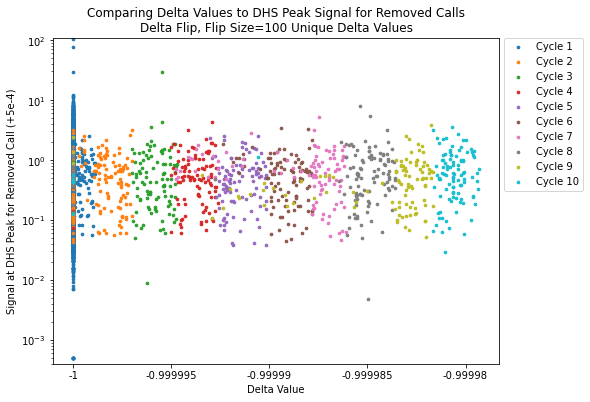

In [15]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(10):
    plt.scatter(removed_delta_all_cycles[i], removed_peak_signal_all_cycles[i]+0.0005, s=7)

# plt.xlim([1.2, 2])
plt.ylim([0.0004, 110])
plt.yscale('log')
plt.legend(['Cycle 1', 'Cycle 2', 'Cycle 3', 'Cycle 4', 'Cycle 5', 'Cycle 6', 'Cycle 7', 'Cycle 8', 'Cycle 9', 'Cycle 10'], loc=(1.01, 0.53))
plt.xticks([-1, -0.999995, -0.99999, -0.999985, -0.99998], [-1, -0.999995, -0.99999, -0.999985, -0.99998])
plt.xlabel('Delta Value')
plt.ylabel('Signal at DHS Peak for Removed Call (+5e-4)')
plt.title('Comparing Delta Values to DHS Peak Signal for Removed Calls\nDelta Flip, Flip Size=100 Unique Delta Values')

In [9]:
#finding peak signal values of added calls
filtered_added_peak_signal_all_cycles = []
for i in range(10):
    print(i)
    filtered_added_peak_signal_single_cycle = []
    for biosample, dhs in zip((filtered_added_flat_inds_all_cycles[i] // n_DHSs), (filtered_added_flat_inds_all_cycles[i] % n_DHSs)):
        filtered_added_peak_signal_single_cycle.append(DHS_peak_signal_array[biosample, dhs])
    filtered_added_peak_signal_single_cycle = np.array(filtered_added_peak_signal_single_cycle)
    filtered_added_peak_signal_all_cycles.append(filtered_added_peak_signal_single_cycle)

0
1
2
3
4
5
6
7
8
9


Text(0.5, 1.0, 'Comparing Delta Values to DHS Peak Signal for Added (Previously 0) Calls\nDelta Flip, Flip Size=100 Unique Delta Values')

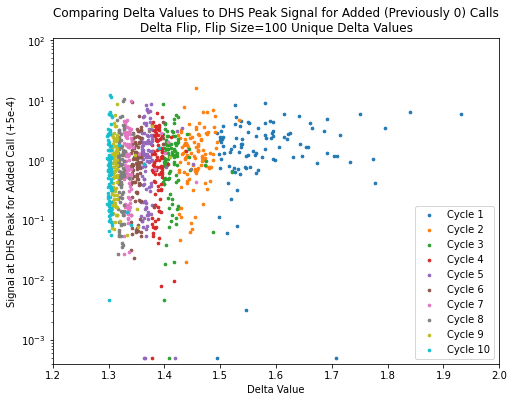

In [16]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(10):
    plt.scatter(filtered_added_delta_all_cycles[i], filtered_added_peak_signal_all_cycles[i]+0.0005, s=7)
    plt.xlim([1.2, 2])
    plt.ylim([0.0004, 110])
    plt.yscale('log')
    
plt.legend(['Cycle 1', 'Cycle 2', 'Cycle 3', 'Cycle 4', 'Cycle 5', 'Cycle 6', 'Cycle 7', 'Cycle 8', 'Cycle 9', 'Cycle 10'])

plt.xlabel('Delta Value')
plt.ylabel('Signal at DHS Peak for Added Call (+5e-4)')
plt.title('Comparing Delta Values to DHS Peak Signal for Added (Previously 0) Calls\nDelta Flip, Flip Size=100 Unique Delta Values')

In [41]:
#finding average signal value of DHS of removed calls
removed_mean_signal_all_cycles = []
for i in range(10):
    mean_signal_vals_single_cycle = np.array(DHS_metadata.loc[(removed_flat_inds_all_cycles[i] % n_DHSs)]['mean_signal'])
    removed_mean_signal_all_cycles.append(mean_signal_vals_single_cycle)

In [10]:
#finding average signal value of DHS of added calls
filtered_added_mean_signal_all_cycles = []
for i in range(10):
    mean_signal_vals_single_cycle = np.array(DHS_metadata.loc[(filtered_added_flat_inds_all_cycles[i] % n_DHSs)]['mean_signal'])
    filtered_added_mean_signal_all_cycles.append(mean_signal_vals_single_cycle)

Text(0.5, 1.07, 'Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS\nDelta Flip, Flip Size=100 Unique Delta Values')

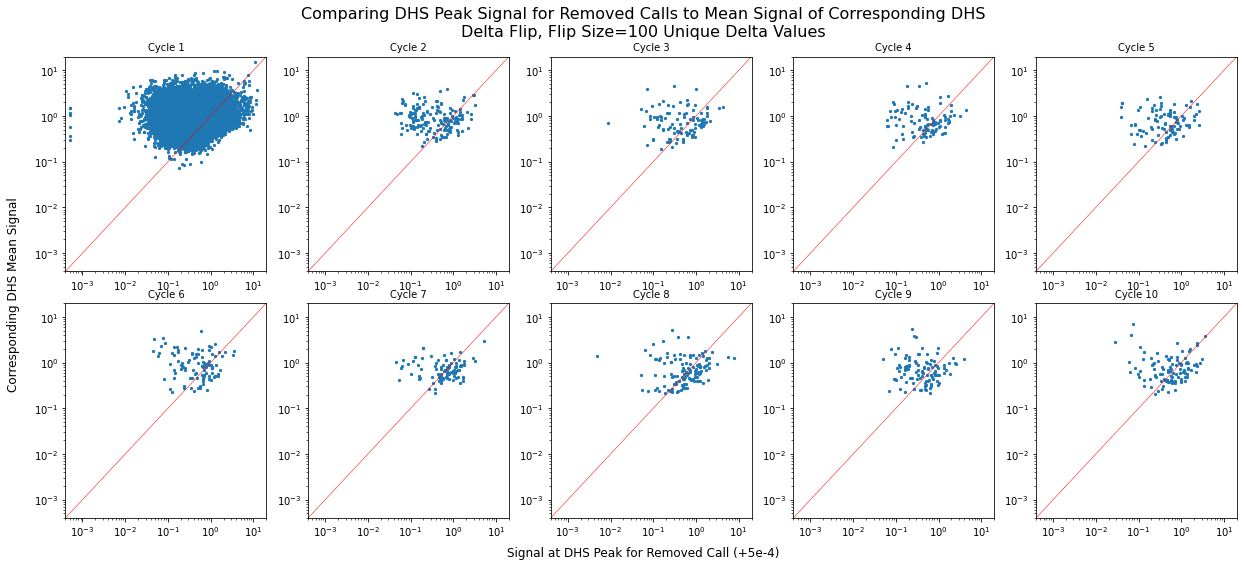

In [51]:
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(17,7))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ax, i in zip(axes, range(10)):
    scat = ax.scatter(removed_peak_signal_all_cycles[i]+0.0005, removed_mean_signal_all_cycles[i], s=5)
    ax.set_title('Cycle ' + str(i+1), fontsize=10)
    ax.set_xlim([0.0004, 20])
    ax.set_ylim([0.0004, 20])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Removed Call (+5e-4)', ha='center', fontsize=12)
fig.text(-0.02, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS\nDelta Flip, Flip Size=100 Unique Delta Values', fontsize=16, x=0.5, y=1.07)

Text(0.5, 1.07, 'Comparing DHS Peak Signal for Added (Previously 0) Calls to Mean Signal of Corresponding DHS\nDelta Flip, Flip Size=100 Unique Delta Values')

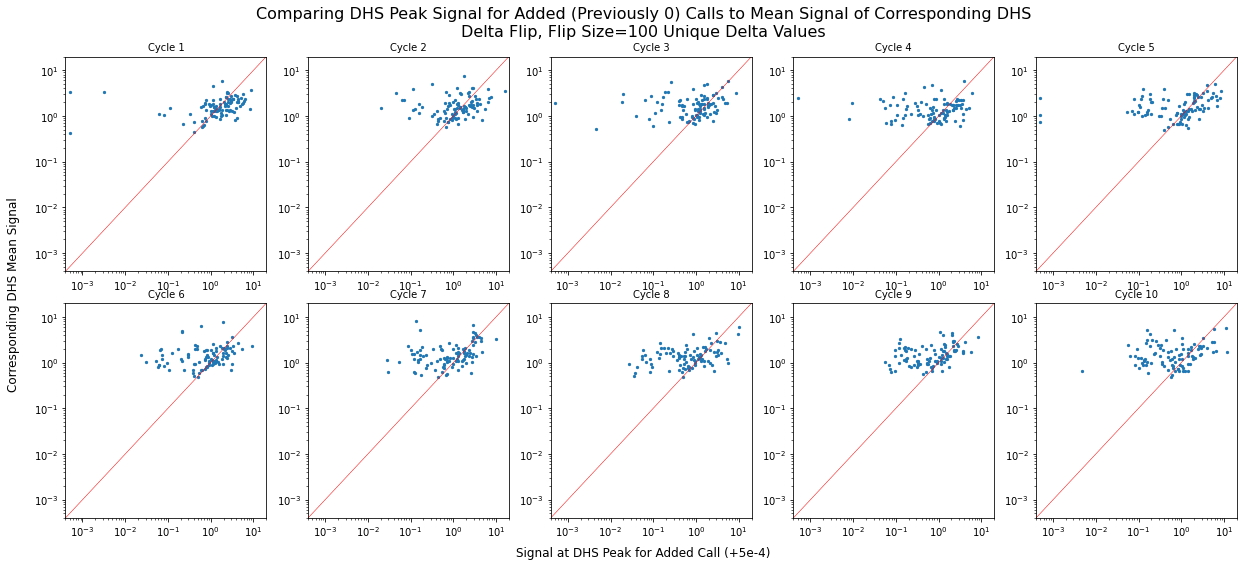

In [122]:
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(17,7))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ax, i in zip(axes, range(10)):
    scat = ax.scatter(filtered_added_peak_signal_all_cycles[i]+0.0005, filtered_added_mean_signal_all_cycles[i], s=5)
    ax.set_title('Cycle ' + str(i+1), fontsize=10)
    ax.set_xlim([0.0004, 20])
    ax.set_ylim([0.0004, 20])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Added Call (+5e-4)', ha='center', fontsize=12)
fig.text(-0.02, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Added (Previously 0) Calls to Mean Signal of Corresponding DHS\nDelta Flip, Flip Size=100 Unique Delta Values', fontsize=16, x=0.5, y=1.07)

**Biosample SPOT Scores**

In [18]:
#how many biosamples have call changes in 10 cycles
changed_biosamples = set()
for i in range(1, 10):
    biosample_inds = removed_flat_inds_all_cycles[i] // n_DHSs
    for j in biosample_inds:
        changed_biosamples.add(j)
len(changed_biosamples)

254

In [11]:
filtered_added_biosample_spot_scores_all_cycles = []
for i in range(10):
    biosample_inds = filtered_added_flat_inds_all_cycles[i] // n_DHSs
    filtered_added_biosample_spot_scores_all_cycles.append(np.array(biosample_df.loc[biosample_inds]['DCC SPOT score']))

In [12]:
removed_biosample_spot_scores_all_cycles = []
for i in range(10):
    biosample_inds = removed_flat_inds_all_cycles[i] // n_DHSs
    removed_biosample_spot_scores_all_cycles.append(np.array(biosample_df.loc[biosample_inds]['DCC SPOT score']))

Text(0.5, 1.0, 'Comparing Delta Values to Corresponding Biosample SPOT Scores for Added (Previously 0) Calls\nDelta Flip, Flip Size=100 Unique Delta Values')

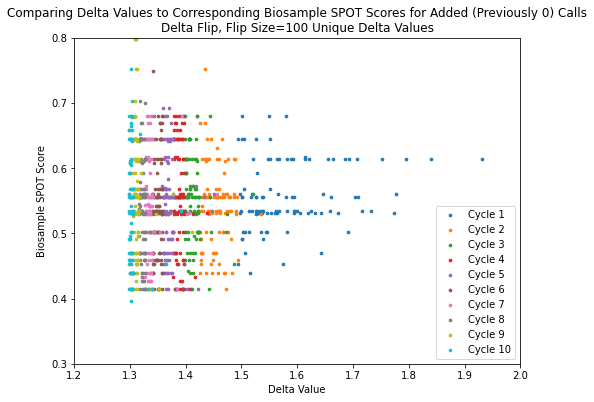

In [141]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(10):
    plt.scatter(filtered_added_delta_all_cycles[i], filtered_added_biosample_spot_scores_all_cycles[i], s=7)
    plt.xlim([1.2, 2])
    plt.ylim([0.3, 0.8])
    
plt.legend(['Cycle 1', 'Cycle 2', 'Cycle 3', 'Cycle 4', 'Cycle 5', 'Cycle 6', 'Cycle 7', 'Cycle 8', 'Cycle 9', 'Cycle 10'])

plt.xlabel('Delta Value')
plt.ylabel('Biosample SPOT Score')
plt.title('Comparing Delta Values to Corresponding Biosample SPOT Scores for Added (Previously 0) Calls\nDelta Flip, Flip Size=100 Unique Delta Values')

Text(0.5, 1.0, 'Comparing Delta Values to Corresponding Biosample SPOT Scores for Removed Calls\nDelta Flip, Flip Size=100 Unique Delta Values')

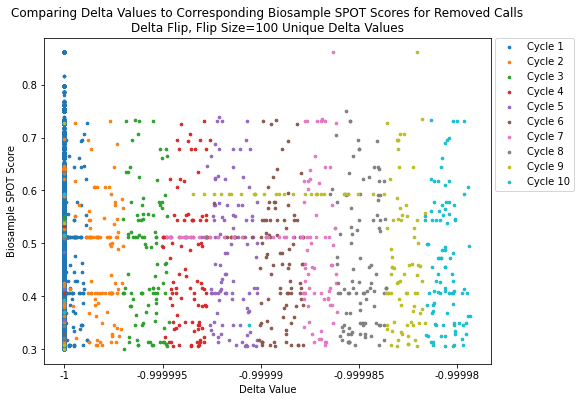

In [17]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(10):
    plt.scatter(removed_delta_all_cycles[i], removed_biosample_spot_scores_all_cycles[i], s=7)
#     plt.xlim([1.2, 2])
    
plt.legend(['Cycle 1', 'Cycle 2', 'Cycle 3', 'Cycle 4', 'Cycle 5', 'Cycle 6', 'Cycle 7', 'Cycle 8', 'Cycle 9', 'Cycle 10'], loc=(1.01, 0.53))
plt.xticks([-1, -0.999995, -0.99999, -0.999985, -0.99998], [-1, -0.999995, -0.99999, -0.999985, -0.99998])
plt.xlabel('Delta Value')
plt.ylabel('Biosample SPOT Score')
plt.title('Comparing Delta Values to Corresponding Biosample SPOT Scores for Removed Calls\nDelta Flip, Flip Size=100 Unique Delta Values')